# 04 - Analisi dei risultati dello sweep AE vs VAE

Questo notebook legge i JSON prodotti dalla modalità `--sweep` della CLI, verifica la loro coerenza, mostra la tabella degli esperimenti e confronta le metriche tra AutoEncoder (AE) e VAE.

Se lo sweep è ancora in esecuzione, i risultati sono parziali: rieseguire le celle quando tutti gli esperimenti sono stati salvati.


In [12]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt

# Cerca la radice del repository risalendo dalle cartelle correnti.
ROOT = Path.cwd()
while not (ROOT / "README.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from eurosat_denoising.report import (
    load_results,
    validate_results,
    experiment_table,
    format_table,
    summarize_comparisons,
    format_summary,
    plot_metric_bars,
    plot_metric_vs_noise,
    plot_baseline_gain,
    plot_ae_vs_vae_scatter,
)

SWEEP_DIR = ROOT / "outputs" / "sweep"
REPORT_DIR = ROOT / "outputs" / "report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Cartella progetto: {ROOT}")
print(f"Cartella sweep: {SWEEP_DIR}")


Cartella progetto: /home/alessandro/Desktop/eurosat-denoising
Cartella sweep: /home/alessandro/Desktop/eurosat-denoising/outputs/sweep


## 1. Caricamento e controllo automatico

Ogni file JSON viene controllato per: campi obbligatori, coerenza tra nome file e parametri, metriche valide, baseline coerente tra i modelli e presenza della coppia AE/VAE per ogni configurazione.


In [13]:
results = load_results(SWEEP_DIR)
print(f"Esperimenti trovati: {len(results)}")

issues = validate_results(results)
if issues:
    print("\nProblemi rilevati:")
    for issue in issues:
        print(f" - {issue}")
else:
    print("\nControllo automatico: nessun problema rilevato.")


Esperimenti trovati: 18

Controllo automatico: nessun problema rilevato.


## 2. Tabella degli esperimenti

`gain` è il guadagno di PSNR rispetto all'immagine rumorosa (baseline): valori positivi indicano che il modello migliora l'input.


In [14]:
rows = experiment_table(results)
print(format_table(rows))


 mod  noise   blur   ep     beta        mse     psnr     ssim       kl     gain
-------------------------------------------------------------------------------
  ae   0.05    0.5    5   0.0001   0.003489    24.57   0.6248   0.0000    -1.31
 vae   0.05    0.5    5   0.0001   0.003672    24.35   0.6158   2.6709    -1.54
  ae   0.05      1    5   0.0001   0.003483    24.58   0.6260   0.0000    -0.41
 vae   0.05      1    5   0.0001   0.003696    24.32   0.6134   2.6791    -0.67
  ae   0.05      2    5   0.0001   0.003628    24.40   0.6184   0.0000    +0.14
 vae   0.05      2    5   0.0001   0.004145    23.82   0.6063   2.7211    -0.44
  ae   0.15    0.5    5   0.0001   0.003749    24.26   0.6099   0.0000    +7.55
 vae   0.15    0.5    5   0.0001   0.003875    24.12   0.6028   2.6753    +7.40
  ae   0.15      1    5   0.0001   0.003725    24.29   0.6103   0.0000    +7.70
 vae   0.15      1    5   0.0001   0.003873    24.12   0.6031   2.7208    +7.53
  ae   0.15      2    5   0.0001   0.003

## 3. Confronto AE vs VAE per configurazione

`dPSNR`, `dMSE` e `dSSIM` sono calcolati come **VAE − AE**:

- `dPSNR > 0` e `dSSIM > 0` → il VAE è migliore;
- `dMSE > 0` → il VAE ha errore quadratico maggiore (peggiore);
- `klVAE` è la divergenza KL media del VAE (per l'AE la KL è 0 per costruzione).


In [15]:
summary = summarize_comparisons(results)
print(format_summary(summary))


noise   blur    dPSNR       dMSE    dSSIM   gainAE   gainVAE     klVAE
----------------------------------------------------------------------
 0.05    0.5    -0.22  +0.000183  -0.0091    -1.31     -1.54    2.6709
 0.05      1    -0.26  +0.000213  -0.0126    -0.41     -0.67    2.6791
 0.05      2    -0.58  +0.000517  -0.0121    +0.14     -0.44    2.7211
 0.15    0.5    -0.14  +0.000126  -0.0072    +7.55     +7.40    2.6753
 0.15      1    -0.17  +0.000148  -0.0072    +7.70     +7.53    2.7208
 0.15      2    -0.04  +0.000039  -0.0030    +7.69     +7.64    2.5800
  0.3    0.5    -0.04  +0.000041  -0.0043   +12.20    +12.15    2.5120
  0.3      1    +0.14  -0.000141  +0.0060   +11.97    +12.12    2.6378
  0.3      2    -0.15  +0.000141  -0.0030   +12.25    +12.10    2.5035


## 4. Metriche per configurazione di degrado

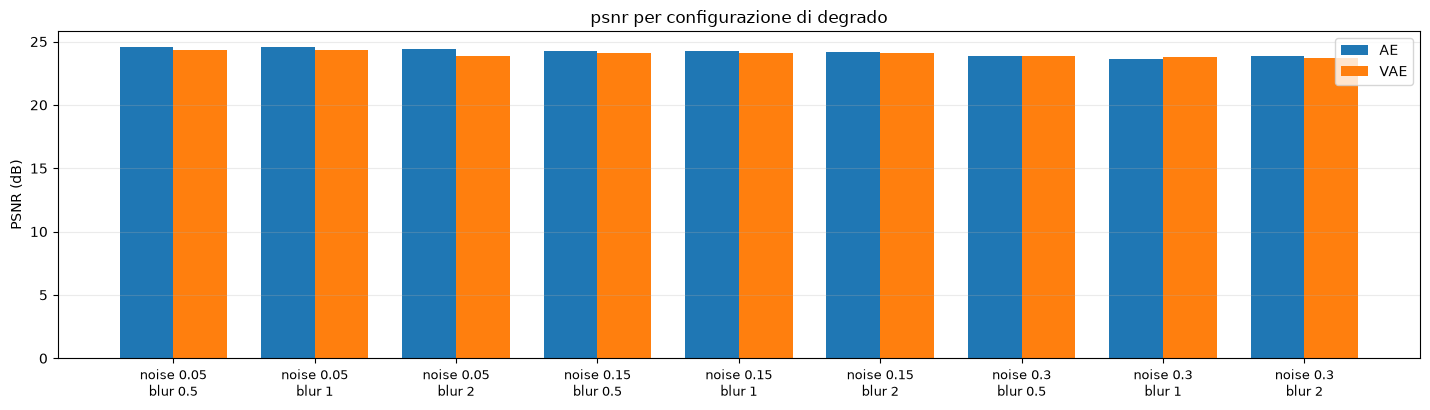

In [16]:
fig = plot_metric_bars(results, "psnr", save_path=REPORT_DIR / "psnr_bars.png", ylabel="PSNR (dB)")
if fig:
    plt.show()


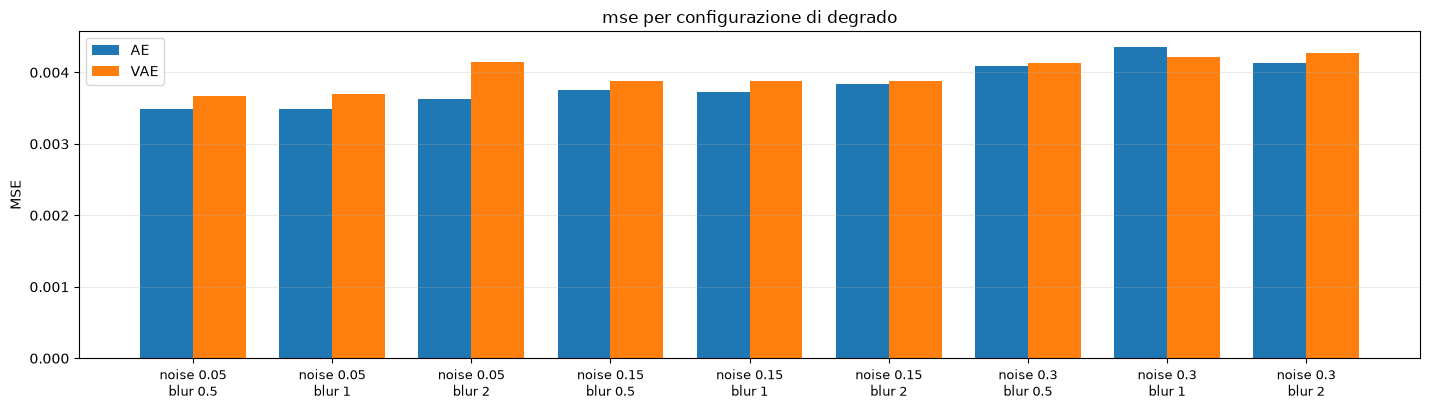

In [17]:
fig = plot_metric_bars(results, "mse", save_path=REPORT_DIR / "mse_bars.png", ylabel="MSE")
if fig:
    plt.show()


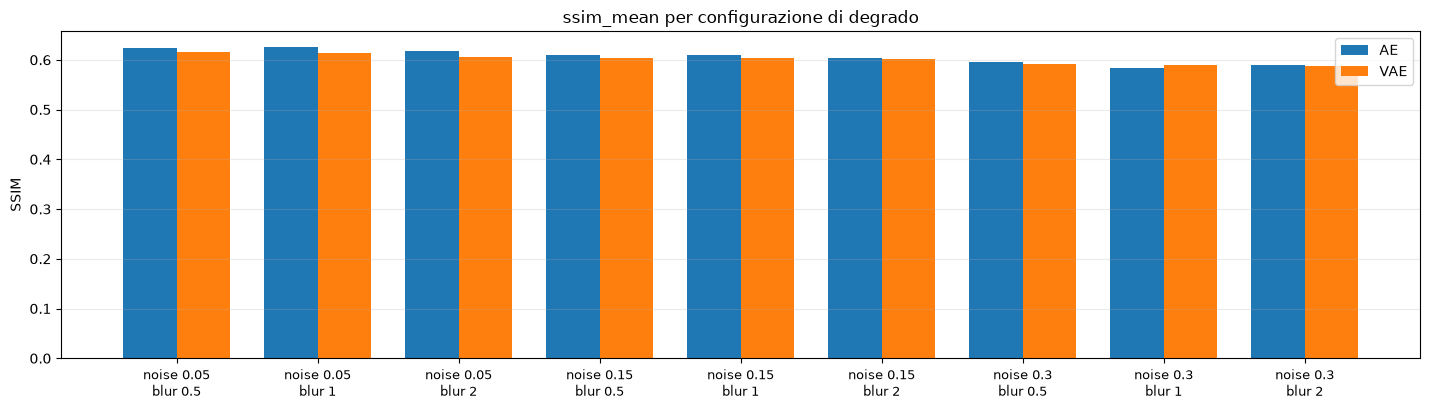

In [18]:
fig = plot_metric_bars(results, "ssim_mean", save_path=REPORT_DIR / "ssim_bars.png", ylabel="SSIM")
if fig:
    plt.show()


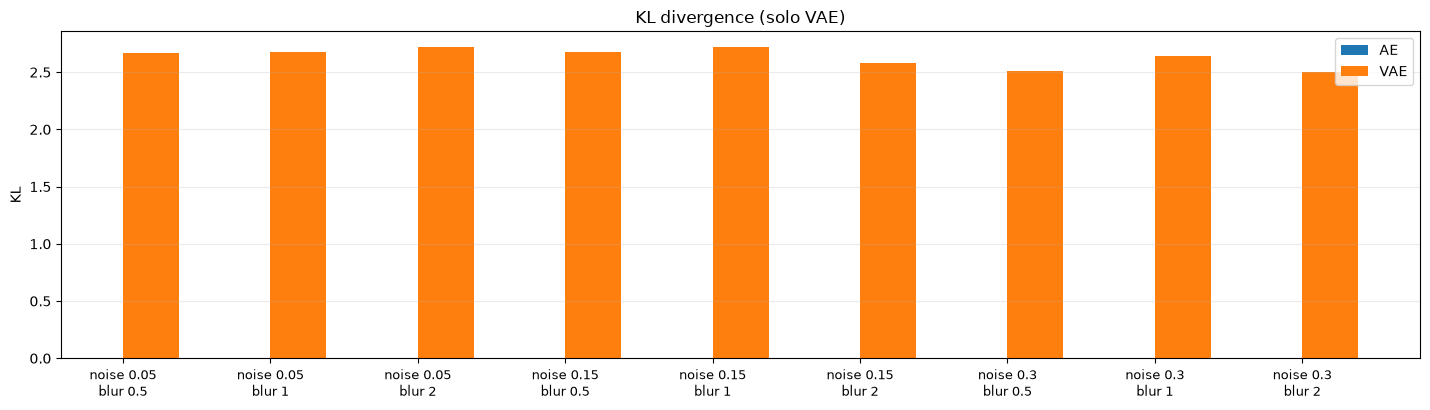

In [19]:
# La KL ha senso solo per il VAE: l'AE non ha una distribuzione latente.
vae_results = [record for record in results if record["model"] == "vae"]
fig = plot_metric_bars(vae_results, "kl", save_path=REPORT_DIR / "kl_bars.png", ylabel="KL", title="KL divergence (solo VAE)")
if fig:
    plt.show()


## 5. PSNR al variare del livello di rumore

Richiede almeno due livelli di rumore nello sweep; se è presente un solo livello la cella lo segnala.


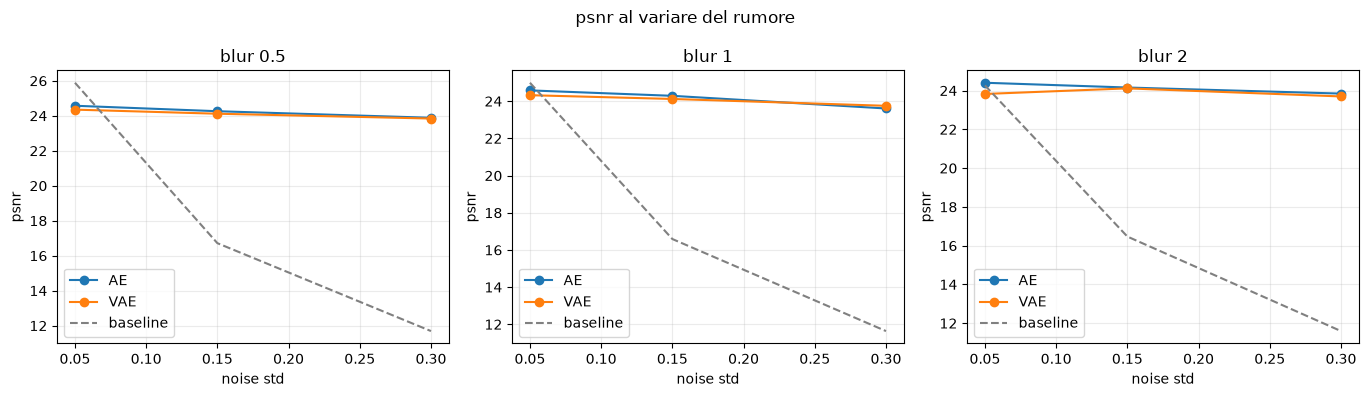

In [20]:
fig = plot_metric_vs_noise(results, "psnr", save_path=REPORT_DIR / "psnr_vs_noise.png")
if fig:
    plt.show()
else:
    print("Servono almeno due livelli di rumore nello sweep per questo grafico.")


## 6. Guadagno rispetto alla baseline rumorosa

Un modello è utile solo se batte l'immagine rumorosa non elaborata: qui il guadagno è espresso in dB di PSNR.


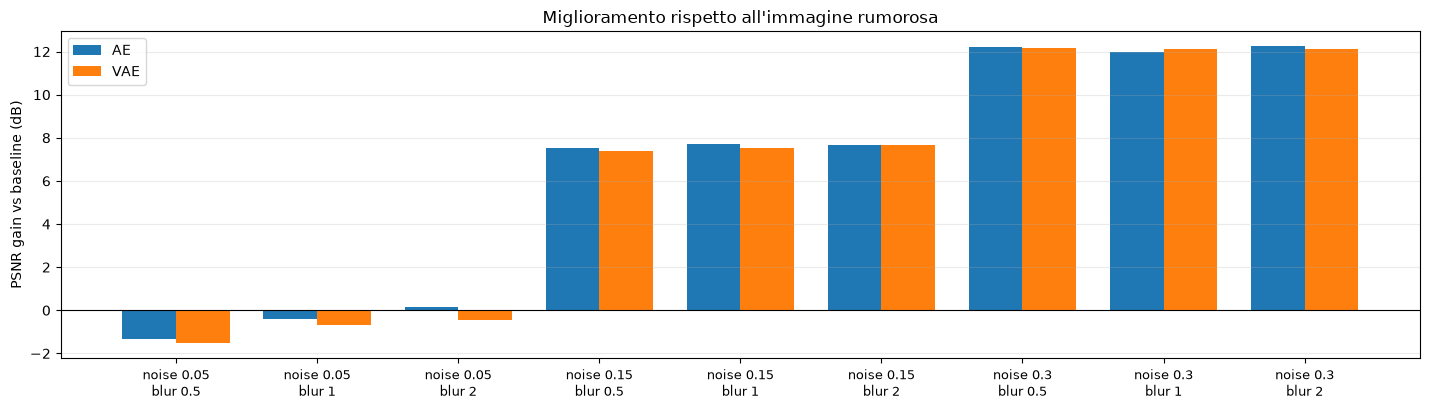

In [21]:
fig = plot_baseline_gain(results, save_path=REPORT_DIR / "psnr_gain.png")
if fig:
    plt.show()


## 7. Confronto diretto AE vs VAE

Ogni punto è una configurazione di degrado con entrambi i modelli. Sopra la diagonale il VAE ha PSNR maggiore; sotto la diagonale vince l'AE.


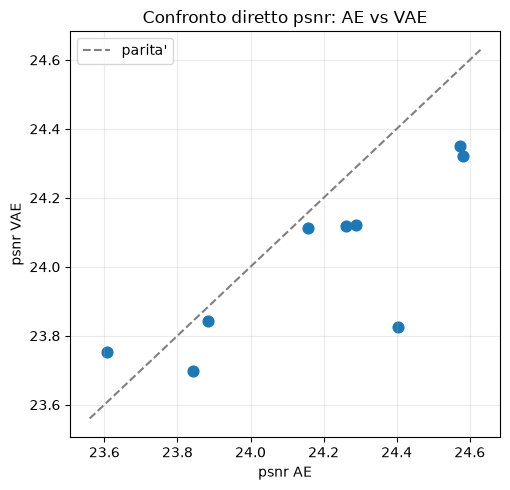

In [22]:
fig = plot_ae_vs_vae_scatter(results, "psnr", save_path=REPORT_DIR / "ae_vs_vae_psnr.png")
if fig:
    plt.show()
else:
    print("Servono sia AE sia VAE per la stessa configurazione.")


## Interpretazione

- **AE vs VAE a parità di configurazione**: l'AE deterministico minimizza direttamente la MSE e in genere ottiene PSNR/SSIM leggermente migliori; il VAE aggiunge il termine KL, che regolarizza lo spazio latente a costo di una lieve perdita di fedeltà.
- **Livello di rumore**: all'aumentare di `sigma` il task è più difficile, quindi PSNR scende e MSE sale per entrambi i modelli e per la baseline.
- **Blur**: il blur gaussiano rimuove informazione ad alta frequenza; il margine rispetto alla baseline può cambiare rispetto al solo rumore.
- **KL**: con `beta` molto piccolo la KL resta contenuta e il VAE si comporta quasi come un AE deterministico; valori elevati indicano un posterior poco allineato al prior.
- **Baseline**: un modello è utile solo se `PSNR > baseline_psnr` e `MSE < baseline_mse`; il guadagno quantifica il miglioramento.
